# Facial Expression Recognition

The FER-2013 dataset created for the Facial Expression Recognition Competition consists of 35887 images with a resolution of 48x48 pixels showing facial expressions corresponding to seven different emotion classes (Angry, Disgust, Fear, Happy, Sad, Surprise and Neutral). 80% of this dataset was used for training and 20% for testing.

## Install Packages and Dataset

In [1]:
# Clone the dataset repository and install required packages
!git clone https://github.com/kemalkilicaslan/Facial-Expression-Recognition-System.git
!pip -q install timm

Cloning into 'Facial-Expression-Recognition-System'...
remote: Enumerating objects: 34081, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 34081 (delta 0), reused 0 (delta 0), pack-reused 34078 (from 1)
Receiving objects: 100% (34081/34081), 53.10 MiB | 36.18 MiB/s, done.
Resolving deltas: 100% (7/7), done.
Updating files: 100% (35900/35900), done.


## Import The Necessary Libraries


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import torch
from torch import nn
from torchvision.datasets import ImageFolder
from torchvision import transforms as T
from torch.utils.data import DataLoader
import timm
from tqdm import tqdm

## Configurations

In [3]:
# Set paths for training and testing datasets
train_img_folder_path = '/content/Facial-Expression-Recognition-System/train'
test_img_folder_path = '/content/Facial-Expression-Recognition-System/test'

In [4]:
# Define hyperparameters for model training
lr = 0.0001
batch_size = 16
epochs = 20
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model_name = 'vgg19_bn'

## Load Dataset

In [5]:
# Define data augmentation for training set to improve model generalization
train_aug = T.Compose([
    T.RandomHorizontalFlip(p =0.5),
    T.RandomRotation(degrees = (-20, +20)),
    T.ToTensor() # PIL / numpy arr -> torch tensor -> (h, w,c) -> (c, h, w)
])

# Define transformation for test set (only convert to tensor, no augmentation)
test_aug = T.Compose([
    T.ToTensor()
])

In [6]:
# Load training and testing datasets using ImageFolder
trainset = ImageFolder(train_img_folder_path, transform = train_aug)
testset = ImageFolder(test_img_folder_path, transform = test_aug)

print(f"Total no. of examples in trainset : {len(trainset)}")
print(f"Total no. of examples in testset : {len(testset)}")

Total no. of examples in trainset : 28709
Total no. of examples in testset : 7178


In [7]:
# Display class-to-index mapping for emotion labels
print(trainset.class_to_idx)

{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


### Visualize Sample Images From Train And Test Sets

Text(0.5, 1.0, '0')

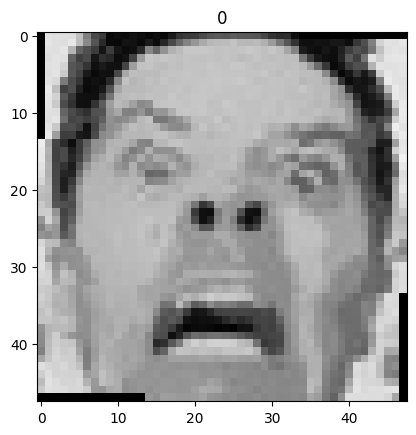

In [8]:
image, label = trainset[40]
plt.imshow(image.permute(1,2,0)) #(h, w, c)
plt.title(label)

Text(0.5, 1.0, '0')

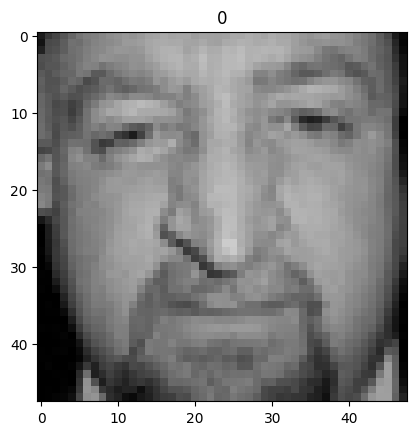

In [9]:
image, label = testset[40]
plt.imshow(image.permute(1,2,0)) #(h, w, c)
plt.title(label)

In [10]:
# Create data loaders for batch processing
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = DataLoader(testset, batch_size, batch_size)

print(f"Total no. of batches in trainloader : {len(trainloader)}")
print(f"Total no. of batches in testloader : {len(testloader)}")

Total no. of batches in trainloader : 1795
Total no. of batches in testloader : 449


In [11]:
# Verify batch shapes
for images, labels in trainloader:
    break

print(f"One image batch shape : {images.shape}")
print(f"One label batch shape : {labels.shape}")

One image batch shape : torch.Size([16, 3, 48, 48])
One label batch shape : torch.Size([16])


## Create Model

In [12]:
class FaceRecognitionModel(nn.Module):
    """
    Custom facial expression recognition model based on VGG19 with batch normalization.
    Uses transfer learning with a modified classifier head for 7 emotion classes.
    """
    def __init__(self, dropout_rate=0.3):
        super(FaceRecognitionModel, self).__init__()
        self.vgg = timm.create_model('vgg19_bn', pretrained=True)

        num_features = self.vgg.head.fc.in_features
        self.vgg.head.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(num_features, 512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 7)
        )

    def forward(self, images, labels=None):
        """
        Forward pass through the network.
        Args:
            images: Input tensor of images
            labels: Ground truth labels (optional, for training)
        Returns:
            logits: Model predictions
            loss: Cross-entropy loss (only during training)
        """
        logits = self.vgg(images)

        if labels is not None:
            loss = nn.CrossEntropyLoss()(logits, labels)
            return logits, loss

        return logits

In [13]:
# Initialize model and move to device (GPU/CPU)
model = FaceRecognitionModel()
model.to(device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/575M [00:00<?, ?B/s]

FaceRecognitionModel(
  (vgg): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (9): ReLU(inplace=True)
      (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (12): ReLU(inplace=True)
      (13): MaxPool2d(kernel_size=2, stride=2, padd

## Create Train and Evaluation Function

In [14]:
def multiclass_accuracy(y_pred, y_true):
    """
    Calculate accuracy for multiclass classification.
    Args:
        y_pred: Predicted logits
        y_true: Ground truth labels
    Returns:
        accuracy: Mean accuracy across batch
    """
    top_p, top_class = y_pred.topk(1, dim=1)
    equals = top_class == y_true.view(*top_class.shape)
    return torch.mean(equals.type(torch.FloatTensor))

In [15]:
def train_func(model, dataloader, optimizer, epoch):
    """
    Training function for one epoch.
    Args:
        model: Neural network model
        dataloader: Training data loader
        optimizer: Optimization algorithm
        epoch: Current epoch number
    Returns:
        avg_loss: Average loss for the epoch
        avg_acc: Average accuracy for the epoch
    """
    model.train()
    total_loss = 0.0
    total_acc = 0.0
    tk = tqdm(dataloader, desc="epoch" + "[train]" + str(epoch + 1) + "/" + str(epochs))

    for t, data in enumerate(tk):
        images, labels = data
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits, loss = model(images, labels)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_loss += loss.item()
        total_acc += multiclass_accuracy(logits, labels)
        tk.set_postfix({
            'loss': '%.6f' % float(total_loss / (t + 1)),
            'acc': '%.6f' % float(total_acc / (t + 1))
        })

    return total_loss / len(dataloader), total_acc / len(dataloader)

In [16]:
def eval_func(model, dataloader, epoch):
    """
    Evaluation function for one epoch.
    Args:
        model: Neural network model
        dataloader: Test data loader
        epoch: Current epoch number
    Returns:
        avg_loss: Average loss for the epoch
        avg_acc: Average accuracy for the epoch
    """
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    tk = tqdm(dataloader, desc="epoch" + "[eval]" + str(epoch + 1) + "/" + str(epochs))

    with torch.no_grad():
        for t, data in enumerate(tk):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            logits, loss = model(images, labels)

            total_loss += loss.item()
            total_acc += multiclass_accuracy(logits, labels)
            tk.set_postfix({
                'loss': '%.6f' % float(total_loss / (t + 1)),
                'acc': '%.6f' % float(total_acc / (t + 1))
            })

    return total_loss / len(dataloader), total_acc / len(dataloader)

## Model Training

In [17]:
# Initialize optimizer with AdamW (Adam with weight decay for better regularization)
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)

In [18]:
# Initialize tracking variable for best model performance
best_test_loss = np.inf

train_losses, train_accs = [], []
test_losses, test_accs = [], []

for i in range(epochs):
    train_loss, train_acc = train_func(model, trainloader, optimizer, i)

    test_loss, test_acc = eval_func(model, testloader, i)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(f"Epoch {i+1}/{epochs} - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, "
          f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}")

    if test_loss < best_test_loss:
        torch.save(model.state_dict(), 'best-weights.pt')
        print(f"Saved best model with loss: {test_loss:.4f}")
        best_test_loss = test_loss

epoch[eval]1/20: 100%|██████████| 449/449 [00:10<00:00, 41.12it/s, loss=1.202841, acc=0.546965]


Epoch 1/20 - Train Loss: 1.4140, Train Acc: 0.4724, Test Loss: 1.2028, Test Acc: 0.5470
Saved best model with loss: 1.2028


epoch[eval]2/20: 100%|██████████| 449/449 [00:09<00:00, 47.09it/s, loss=1.198105, acc=0.566732]


Epoch 2/20 - Train Loss: 1.2018, Train Acc: 0.5572, Test Loss: 1.1981, Test Acc: 0.5667
Saved best model with loss: 1.1981


epoch[eval]3/20: 100%|██████████| 449/449 [00:09<00:00, 45.91it/s, loss=1.053378, acc=0.613168]


...

Epoch 18/20 - Train Loss: 0.6018, Train Acc: 0.7907, Test Loss: 1.0928, Test Acc: 0.6798


epoch[eval]19/20: 100%|██████████| 449/449 [00:09<00:00, 47.37it/s, loss=1.134543, acc=0.675779]


Epoch 19/20 - Train Loss: 0.5722, Train Acc: 0.8022, Test Loss: 1.1345, Test Acc: 0.6758


epoch[eval]20/20: 100%|██████████| 449/449 [00:09<00:00, 47.36it/s, loss=1.069292, acc=0.665367]

Epoch 20/20 - Train Loss: 0.5484, Train Acc: 0.8115, Test Loss: 1.0693, Test Acc: 0.6654


## Result

In [ ]:
# Result Visualization
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Loss vs Epoch', 'Accuracy vs Epoch')
)

fig.add_trace(
    go.Scatter(y=train_losses, mode='lines+markers', name='Train Loss',
               line=dict(color='blue')),
    row=1, col=1
)
fig.add_trace(
    go.Scatter(y=test_losses, mode='lines+markers', name='Test Loss',
               line=dict(color='red')),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(y=train_accs, mode='lines+markers', name='Train Accuracy',
               line=dict(color='green')),
    row=1, col=2
)
fig.add_trace(
    go.Scatter(y=test_accs, mode='lines+markers', name='Test Accuracy',
               line=dict(color='orange')),
    row=1, col=2
)

fig.update_xaxes(title_text="Epoch", row=1, col=1)
fig.update_xaxes(title_text="Epoch", row=1, col=2)
fig.update_yaxes(title_text="Loss", row=1, col=1)
fig.update_yaxes(title_text="Accuracy", row=1, col=2)

fig.update_layout(
    template="plotly_dark",
    height=500,
    width=1200,
    showlegend=True,
    title_text="Training History"
)

fig.show()

In [20]:
## Prediction Visualization
def view_classify(img, ps):
    """
    Visualize prediction results with image and probability bar chart.
    Args:
        img: Input image tensor
        ps: Prediction probabilities for each class
    """
    classes = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

    ps = ps.data.cpu().numpy().squeeze()
    img = img.numpy().transpose(1,2,0)

    fig, (ax1, ax2) = plt.subplots(figsize=(5,9), ncols=2)
    ax1.imshow(img)
    ax1.axis('off')
    ax2.barh(classes, ps)
    ax2.set_aspect(0.1)
    ax2.set_yticks(classes)
    ax2.set_yticklabels(classes)
    ax2.set_title('Class Probability')
    ax2.set_xlim(0, 1.1)

    plt.tight_layout()

    return None

True Label: angry, Predicted Label: angry, Predicted Probability: 0.5937
True Label: disgust, Predicted Label: surprise, Predicted Probability: 0.6077
True Label: fear, Predicted Label: fear, Predicted Probability: 0.3767
True Label: happy, Predicted Label: happy, Predicted Probability: 0.9841
True Label: neutral, Predicted Label: neutral, Predicted Probability: 0.5031
True Label: sad, Predicted Label: fear, Predicted Probability: 0.4081
True Label: surprise, Predicted Label: surprise, Predicted Probability: 0.9673


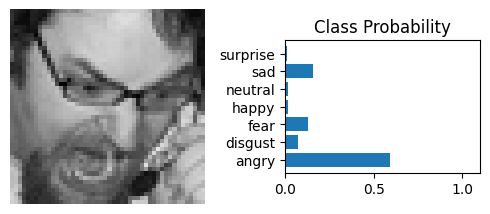

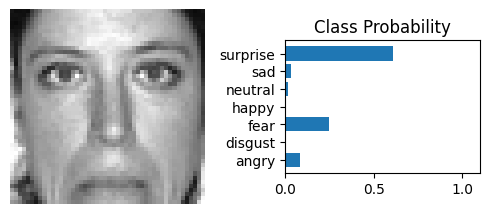

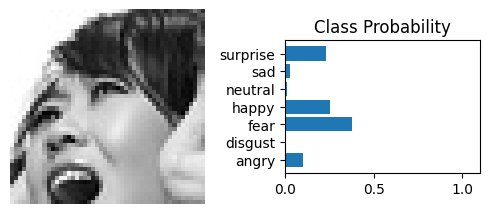

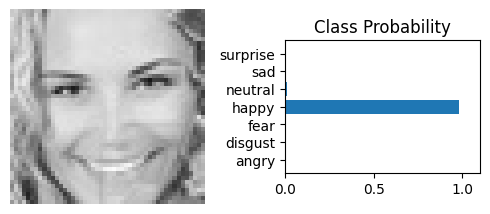

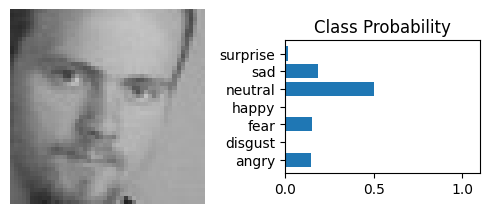

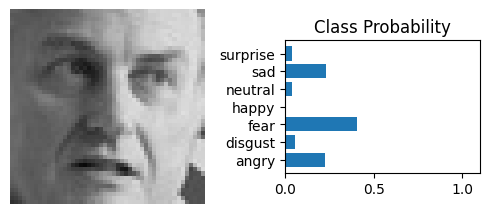

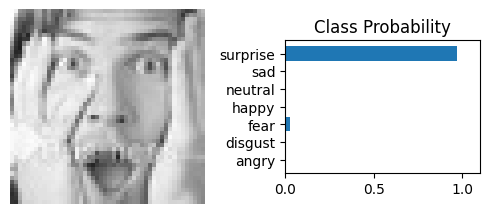

In [21]:
def predict(model, dataloader, num_class=7):
    """
    Make predictions on test data and visualize results for each emotion class.
    Args:
        model: Trained model
        dataloader: Test data loader
        num_class: Number of emotion classes (default: 7)
    """
    model.eval()
    images, labels = next(iter(DataLoader(testset, batch_size=len(testset))))
    images, labels = images.to(device), labels.to(device)

    with torch.no_grad():
        logits = model(images)
        ps = torch.softmax(logits, dim=1)
        top_p, top_class = ps.topk(1, dim=1)

    for i in range(num_class):
        for j, image in enumerate(images):
            label = labels[j].item()
            predicted_class = top_class[j].item()
            predicted_prob = top_p[j].item()

            predicted_label = trainset.classes[predicted_class]
            true_label = trainset.classes[label]

            if true_label == trainset.classes[i]:
                print(f"True Label: {true_label}, Predicted Label: {predicted_label}, "
                      f"Predicted Probability: {predicted_prob:.4f}")
                view_classify(image.cpu(), ps[j])
                break

# Load best model weights and make predictions
model.load_state_dict(torch.load('best-weights.pt'))
predict(model, testloader, num_class=7)